## **Importation et initialisation des données**

In [ ]:

%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import random
import uuid
import os



## **Génération aléatoire des données (15 villes)**

In [ ]:

np.random.seed(42)  # Pour reproductibilité
n_cities = 15
cities = np.random.rand(n_cities, 2) * 100  # Coordonnées (x, y) entre 0 et 100



## **Calcul des distances euclidiennes entre toutes les villes**

In [ ]:

def compute_distances(cities):
    n = len(cities)
    distances = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            distances[i, j] = np.sqrt((cities[i, 0] - cities[j, 0])**2 + (cities[i, 1] - cities[j, 1])**2)
    return distances

distances = compute_distances(cities)



## **Fonction d'aptitude**

In [ ]:

def fitness(route):
    total_distance = 0
    for i in range(len(route)):
        from_city = route[i]
        to_city = route[(i + 1) % len(route)]  # Retour à la première ville
        total_distance += distances[from_city, to_city]
    return 1 / total_distance  # Fitness inversement proportionnel à la distance



## **Initialisation de la population**

In [ ]:

def initialize_population(pop_size, n_cities):
    population = []
    for _ in range(pop_size):
        # Ville 0 en premier, puis permutation des villes 1 à 14
        remaining_cities = list(np.random.permutation(range(1, n_cities)))
        route = [0] + remaining_cities
        population.append(route)
    return population



## **Sélection par tournoi**

In [26]:

def tournament_selection(population, k=10):
    tournament = random.sample(population, k)
    return max(tournament, key=fitness)



In [33]:


def roulette_selection(population):
    fitness_scores = [fitness(route) for route in population]
    total_fitness = sum(fitness_scores)
    probabilities = [f / total_fitness for f in fitness_scores]
    return random.choices(population, weights=probabilities, k=1)[0]

def rank_selection(population):
    fitness_scores = [(fitness(route), idx) for idx, route in enumerate(population)]
    sorted_indices = [idx for _, idx in sorted(fitness_scores, reverse=True)]
    n = len(population)
    probabilities = [(n - i) / (n * (n + 1) / 2) for i in range(n)]
    return population[random.choices(sorted_indices, weights=probabilities, k=1)[0]]

def sus_selection(population):
    fitness_scores = [fitness(route) for route in population]
    total_fitness = sum(fitness_scores)
    n = len(population)
    step = total_fitness / n
    start = random.uniform(0, step)
    cumulative_fitness = 0
    for i, f in enumerate(fitness_scores):
        cumulative_fitness += f
        if cumulative_fitness >= start:
            return population[i]
    return population[-1]

def elitist_selection(population):
    return max(population, key=fitness)

def truncation_selection(population, proportion=0.5):
    fitness_scores = [(fitness(route), route) for route in population]
    sorted_routes = [route for _, route in sorted(fitness_scores, reverse=True)]
    n_select = int(len(population) * proportion)
    return random.choice(sorted_routes[:n_select])

## **Croisement (Ordered Crossover)**

In [27]:

def crossover(parent1, parent2):
    size = len(parent1)
    start, end = sorted(random.sample(range(1, size), 2))  # Exclut position 0
    child = [-1] * size
    child[0] = 0  # Ville 0 reste en première position
    # Copier le segment du parent1
    child[start:end] = parent1[start:end]
    # Compléter avec les villes du parent2 dans l'ordre, en excluant la ville 0
    pos = end
    for city in parent2[1:]:  # Ignorer la ville 0 du parent2
        if city not in child:
            if pos >= size:
                pos = 1  # Commencer après la ville 0
            while child[pos] != -1:
                pos += 1
                if pos >= size:
                    pos = 1
            child[pos] = city
    return child



## **Mutation**

In [28]:

def mutate(route, mutation_rate=0.01):
    route = route.copy()  # Éviter de modifier l'original
    if random.random() < mutation_rate:
        i, j = random.sample(range(1, len(route)), 2)  # Exclut position 0
        route[i], route[j] = route[j], route[i]
    return route



## **Fonctions utilitaires**

In [34]:

def print_route(route):
    return " -> ".join(map(str, route + [route[0]]))

def plot_route(route, gen, distance):
    plt.figure(figsize=(8, 6))
    for i, city in enumerate(cities):
        plt.scatter(city[0], city[1], c='blue', s=100)
        plt.text(city[0] + 1, city[1] + 1, f'Ville {i}', fontsize=9)
    route_coords = [cities[i] for i in route] + [cities[route[0]]]
    route_coords = np.array(route_coords)
    plt.plot(route_coords[:, 0], route_coords[:, 1], 'r-', linewidth=1)
    plt.title(f"Chemin à la génération {gen} (Distance: {distance:.2f})")
    plt.xlabel("X")
    plt.ylabel("Y")
    plt.grid(True)
    plt.savefig(f'route_gen_{gen}.png')
    plt.show()
    plt.close()



## **Algorithme génétique principal**


Génération 0:
Itinéraire : 0 -> 12 -> 2 -> 7 -> 13 -> 8 -> 1 -> 4 -> 6 -> 14 -> 10 -> 5 -> 3 -> 11 -> 9 -> 0
Score de fitness : 0.001853
Distance totale : 539.65


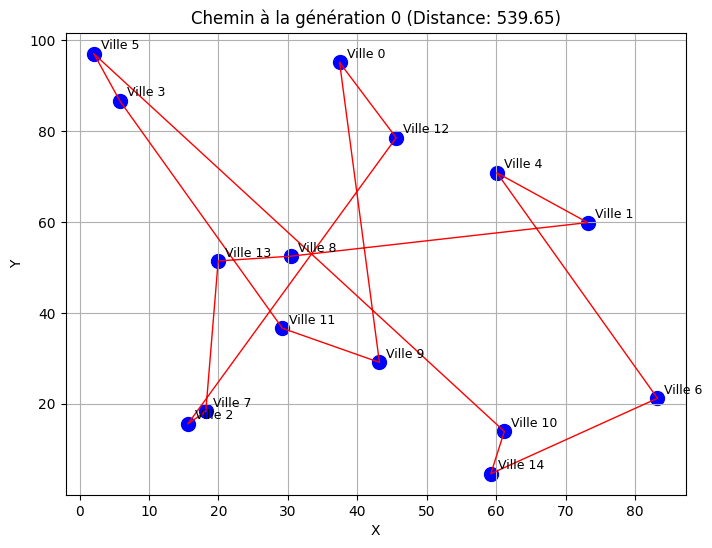


Génération 1:
Itinéraire : 0 -> 5 -> 12 -> 3 -> 13 -> 8 -> 1 -> 4 -> 6 -> 14 -> 10 -> 9 -> 7 -> 2 -> 11 -> 0
Score de fitness : 0.002154
Distance totale : 464.27

Génération 2:
Itinéraire : 0 -> 12 -> 8 -> 1 -> 4 -> 6 -> 14 -> 10 -> 9 -> 7 -> 11 -> 13 -> 2 -> 3 -> 5 -> 0
Score de fitness : 0.002241
Distance totale : 446.29

Génération 3:
Itinéraire : 0 -> 12 -> 13 -> 8 -> 1 -> 4 -> 6 -> 14 -> 10 -> 9 -> 7 -> 2 -> 11 -> 3 -> 5 -> 0
Score de fitness : 0.002491
Distance totale : 401.38

Génération 4:
Itinéraire : 0 -> 12 -> 13 -> 8 -> 1 -> 4 -> 6 -> 14 -> 10 -> 9 -> 7 -> 2 -> 11 -> 3 -> 5 -> 0
Score de fitness : 0.002491
Distance totale : 401.38

Génération 5:
Itinéraire : 0 -> 12 -> 13 -> 8 -> 1 -> 4 -> 6 -> 14 -> 10 -> 9 -> 7 -> 2 -> 11 -> 3 -> 5 -> 0
Score de fitness : 0.002491
Distance totale : 401.38

Génération 6:
Itinéraire : 0 -> 12 -> 13 -> 8 -> 1 -> 4 -> 6 -> 14 -> 10 -> 9 -> 2 -> 7 -> 11 -> 3 -> 5 -> 0
Score de fitness : 0.002493
Distance totale : 401.18

Génération 7:
Itinéra

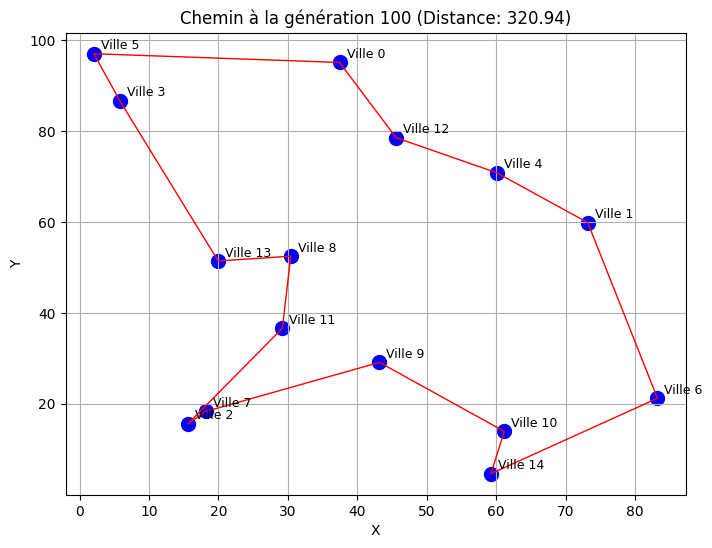


Génération 101:
Itinéraire : 0 -> 12 -> 4 -> 1 -> 6 -> 14 -> 10 -> 9 -> 7 -> 2 -> 11 -> 8 -> 13 -> 3 -> 5 -> 0
Score de fitness : 0.003116
Distance totale : 320.94

Génération 102:
Itinéraire : 0 -> 12 -> 4 -> 1 -> 6 -> 14 -> 10 -> 9 -> 7 -> 2 -> 11 -> 8 -> 13 -> 3 -> 5 -> 0
Score de fitness : 0.003116
Distance totale : 320.94

Génération 103:
Itinéraire : 0 -> 12 -> 4 -> 1 -> 6 -> 14 -> 10 -> 9 -> 7 -> 2 -> 11 -> 8 -> 13 -> 3 -> 5 -> 0
Score de fitness : 0.003116
Distance totale : 320.94

Génération 104:
Itinéraire : 0 -> 12 -> 4 -> 1 -> 6 -> 14 -> 10 -> 9 -> 7 -> 2 -> 11 -> 8 -> 13 -> 3 -> 5 -> 0
Score de fitness : 0.003116
Distance totale : 320.94

Génération 105:
Itinéraire : 0 -> 12 -> 4 -> 1 -> 6 -> 14 -> 10 -> 9 -> 7 -> 2 -> 11 -> 8 -> 13 -> 3 -> 5 -> 0
Score de fitness : 0.003116
Distance totale : 320.94

Génération 106:
Itinéraire : 0 -> 12 -> 4 -> 1 -> 6 -> 14 -> 10 -> 9 -> 7 -> 2 -> 11 -> 8 -> 13 -> 3 -> 5 -> 0
Score de fitness : 0.003116
Distance totale : 320.94

Génératio

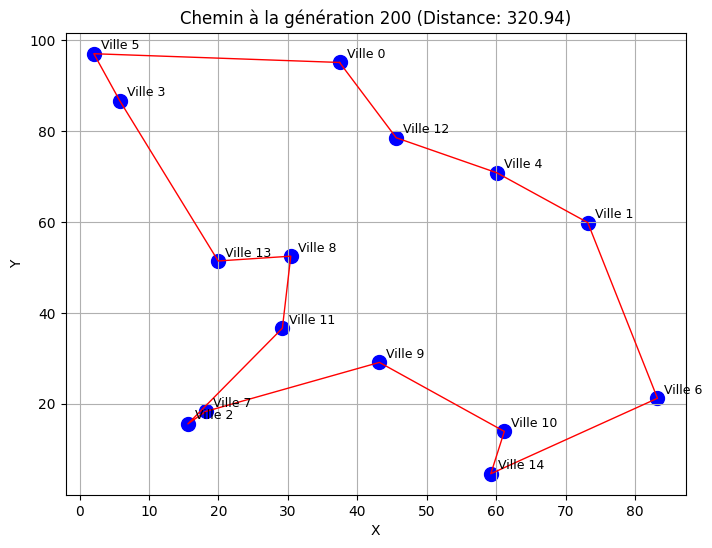


Génération 201:
Itinéraire : 0 -> 12 -> 4 -> 1 -> 6 -> 14 -> 10 -> 9 -> 7 -> 2 -> 11 -> 8 -> 13 -> 3 -> 5 -> 0
Score de fitness : 0.003116
Distance totale : 320.94

Génération 202:
Itinéraire : 0 -> 12 -> 4 -> 1 -> 6 -> 14 -> 10 -> 9 -> 7 -> 2 -> 11 -> 8 -> 13 -> 3 -> 5 -> 0
Score de fitness : 0.003116
Distance totale : 320.94

Génération 203:
Itinéraire : 0 -> 12 -> 4 -> 1 -> 6 -> 14 -> 10 -> 9 -> 7 -> 2 -> 11 -> 8 -> 13 -> 3 -> 5 -> 0
Score de fitness : 0.003116
Distance totale : 320.94

Génération 204:
Itinéraire : 0 -> 12 -> 4 -> 1 -> 6 -> 14 -> 10 -> 9 -> 7 -> 2 -> 11 -> 8 -> 13 -> 3 -> 5 -> 0
Score de fitness : 0.003116
Distance totale : 320.94

Génération 205:
Itinéraire : 0 -> 12 -> 4 -> 1 -> 6 -> 14 -> 10 -> 9 -> 7 -> 2 -> 11 -> 8 -> 13 -> 3 -> 5 -> 0
Score de fitness : 0.003116
Distance totale : 320.94

Génération 206:
Itinéraire : 0 -> 12 -> 4 -> 1 -> 6 -> 14 -> 10 -> 9 -> 7 -> 2 -> 11 -> 8 -> 13 -> 3 -> 5 -> 0
Score de fitness : 0.003116
Distance totale : 320.94

Génératio

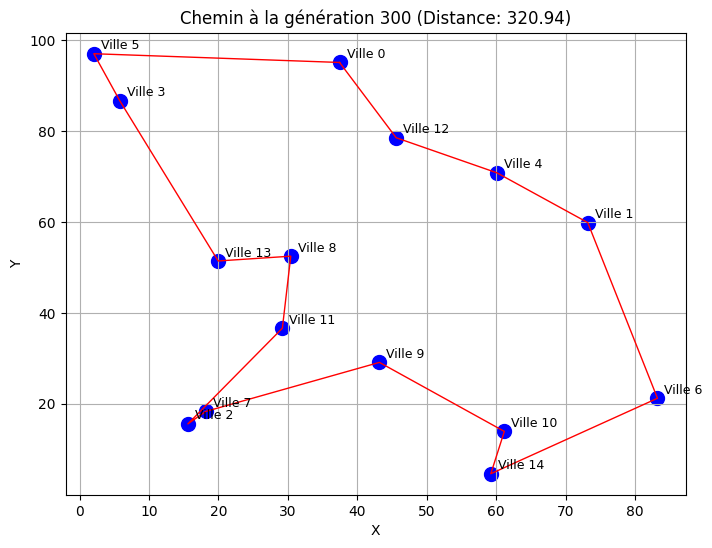


Génération 301:
Itinéraire : 0 -> 12 -> 4 -> 1 -> 6 -> 14 -> 10 -> 9 -> 7 -> 2 -> 11 -> 8 -> 13 -> 3 -> 5 -> 0
Score de fitness : 0.003116
Distance totale : 320.94

Génération 302:
Itinéraire : 0 -> 12 -> 4 -> 1 -> 6 -> 14 -> 10 -> 9 -> 7 -> 2 -> 11 -> 8 -> 13 -> 3 -> 5 -> 0
Score de fitness : 0.003116
Distance totale : 320.94

Génération 303:
Itinéraire : 0 -> 12 -> 4 -> 1 -> 6 -> 14 -> 10 -> 9 -> 7 -> 2 -> 11 -> 8 -> 13 -> 3 -> 5 -> 0
Score de fitness : 0.003116
Distance totale : 320.94

Génération 304:
Itinéraire : 0 -> 12 -> 4 -> 1 -> 6 -> 14 -> 10 -> 9 -> 7 -> 2 -> 11 -> 8 -> 13 -> 3 -> 5 -> 0
Score de fitness : 0.003116
Distance totale : 320.94

Génération 305:
Itinéraire : 0 -> 12 -> 4 -> 1 -> 6 -> 14 -> 10 -> 9 -> 7 -> 2 -> 11 -> 8 -> 13 -> 3 -> 5 -> 0
Score de fitness : 0.003116
Distance totale : 320.94

Génération 306:
Itinéraire : 0 -> 12 -> 4 -> 1 -> 6 -> 14 -> 10 -> 9 -> 7 -> 2 -> 11 -> 8 -> 13 -> 3 -> 5 -> 0
Score de fitness : 0.003116
Distance totale : 320.94

Génératio

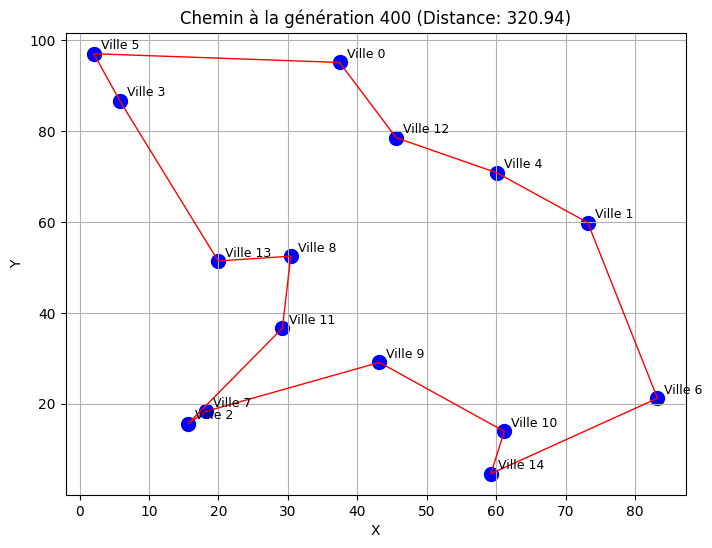


Génération 401:
Itinéraire : 0 -> 12 -> 4 -> 1 -> 6 -> 14 -> 10 -> 9 -> 7 -> 2 -> 11 -> 8 -> 13 -> 3 -> 5 -> 0
Score de fitness : 0.003116
Distance totale : 320.94

Génération 402:
Itinéraire : 0 -> 12 -> 4 -> 1 -> 6 -> 14 -> 10 -> 9 -> 7 -> 2 -> 11 -> 8 -> 13 -> 3 -> 5 -> 0
Score de fitness : 0.003116
Distance totale : 320.94

Génération 403:
Itinéraire : 0 -> 12 -> 4 -> 1 -> 6 -> 14 -> 10 -> 9 -> 7 -> 2 -> 11 -> 8 -> 13 -> 3 -> 5 -> 0
Score de fitness : 0.003116
Distance totale : 320.94

Génération 404:
Itinéraire : 0 -> 12 -> 4 -> 1 -> 6 -> 14 -> 10 -> 9 -> 7 -> 2 -> 11 -> 8 -> 13 -> 3 -> 5 -> 0
Score de fitness : 0.003116
Distance totale : 320.94

Génération 405:
Itinéraire : 0 -> 12 -> 4 -> 1 -> 6 -> 14 -> 10 -> 9 -> 7 -> 2 -> 11 -> 8 -> 13 -> 3 -> 5 -> 0
Score de fitness : 0.003116
Distance totale : 320.94

Génération 406:
Itinéraire : 0 -> 12 -> 4 -> 1 -> 6 -> 14 -> 10 -> 9 -> 7 -> 2 -> 11 -> 8 -> 13 -> 3 -> 5 -> 0
Score de fitness : 0.003116
Distance totale : 320.94

Génératio

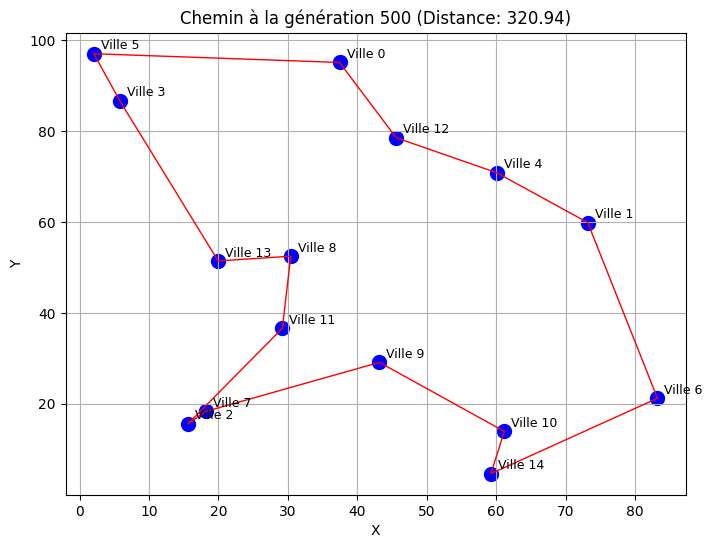

In [38]:

def genetic_algorithm(pop_size=100, generations=500, mutation_rate=0.01):
    population = initialize_population(pop_size, n_cities)
    best_route = None
    best_fitness = -float('inf')
    best_distance = float('inf')
    fitness_history = []  # Pour stocker l'évolution des fitness

    for gen in range(generations):
        # Évaluation
        fitness_scores = [fitness(route) for route in population]
        current_best_idx = np.argmax(fitness_scores)
        current_best_fitness = fitness_scores[current_best_idx]
        current_best_route = population[current_best_idx]
        current_best_distance = 1 / current_best_fitness

        # Mise à jour du meilleur chemin
        if current_best_fitness > best_fitness:
            best_fitness = current_best_fitness
            best_route = current_best_route
            best_distance = current_best_distance

        # Stocker le fitness pour le graphique
        fitness_history.append(current_best_fitness)

        # Affichage des informations pour la génération
        print(f"\nGénération {gen}:")
        print(f"Itinéraire : {print_route(current_best_route)}")
        print(f"Score de fitness : {current_best_fitness:.6f}")
        print(f"Distance totale : {current_best_distance:.2f}")

        # Afficher le chemin toutes les 100 générations
        if gen % 100 == 0:
            plot_route(current_best_route, gen, current_best_distance)

        # Sélection et création de la nouvelle population
        new_population = []
        for _ in range(pop_size // 2):
            parent1 = tournament_selection(population)
            parent2 = tournament_selection(population)
            child1 = crossover(parent1, parent2)
            child2 = crossover(parent2, parent1)
            new_population.append(mutate(child1, mutation_rate))
            new_population.append(mutate(child2, mutation_rate))

        # Remplacement
        population = new_population

    # Afficher le dernier chemin
    plot_route(best_route, generations, best_distance)

    return best_route, best_distance, fitness_history

# Exécuter l'algorithme
best_route, best_distance, fitness_history = genetic_algorithm()



##  **Visualisation du meilleur chemin**

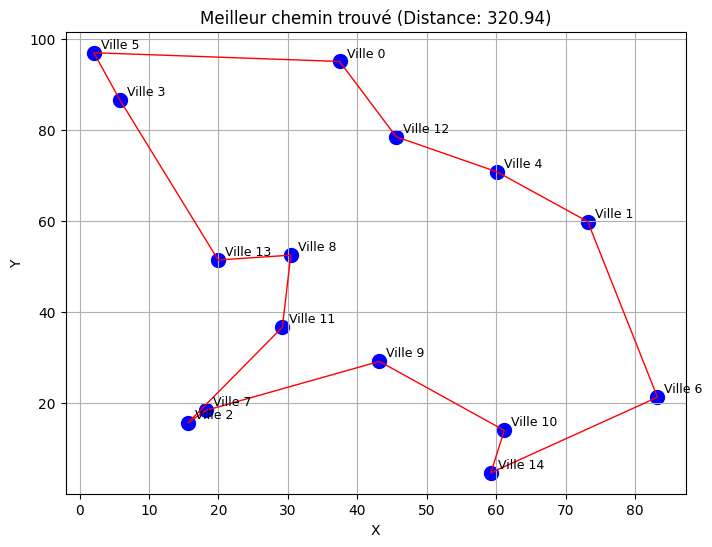

In [39]:


plt.figure(figsize=(8, 6))
for i, city in enumerate(cities):
    plt.scatter(city[0], city[1], c='blue', s=100)
    plt.text(city[0] + 1, city[1] + 1, f'Ville {i}', fontsize=9)
route_coords = [cities[i] for i in best_route] + [cities[best_route[0]]]
route_coords = np.array(route_coords)
plt.plot(route_coords[:, 0], route_coords[:, 1], 'r-', linewidth=1)
plt.title(f"Meilleur chemin trouvé (Distance: {best_distance:.2f})")
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(True)
plt.savefig('tsp_solution.png')
plt.show()
plt.close()



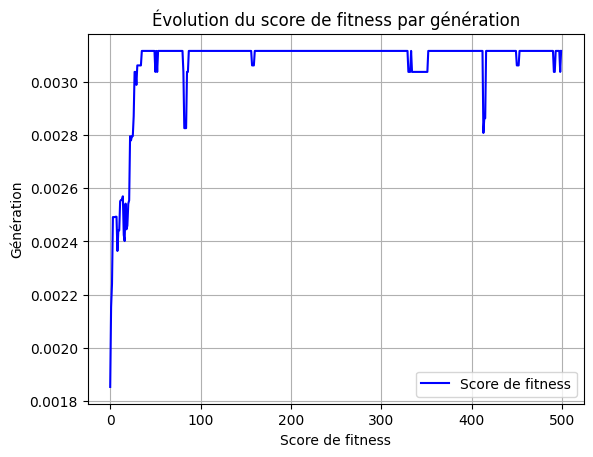

In [ ]:
# Visualisation de l'évolution du fitness
plt.figure(figsize=(8, 6))
plt.plot(range(len(fitness_history)), fitness_history,  'b-', label='Score de fitness')
plt.title("Évolution du score de fitness par génération")
plt.ylabel("Génération")
plt.xlabel("Score de fitness")
plt.grid(True)
plt.legend()
plt.savefig('fitness_evolution.png')
plt.show()
plt.close()